In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:
# -----------------------------
# 1. Load Dataset
# -----------------------------

df = pd.read_excel(r"C:\Users\kolla\Downloads\water_management_raw.xlsx")

# -----------------------------
# 2. Data Cleaning
# -----------------------------

# clean column names
df.columns = df.columns.str.strip()

# remove spaces from text columns
df = df.apply(lambda x: x.str.strip() if x.dtype == "object" else x)

# fill missing values
df.fillna("No Information", inplace=True)

# -----------------------------
# 3. Create Analysis Tables
# -----------------------------

# Climate distribution
climate_dist = df["Climatic Conditions"].value_counts().reset_index()
climate_dist.columns = ["Climatic Condition", "Count"]

# Land size categories
def categorize_land(x):
    x = str(x).lower()
    if "small" in x:
        return "Small"
    elif "medium" in x:
        return "Medium"
    elif "large" in x:
        return "Large"
    else:
        return "No Information"

df["Land Category"] = df["Land Holdings"].apply(categorize_land)

land_dist = df["Land Category"].value_counts().reset_index()
land_dist.columns = ["Land Category", "Count"]

# Crop distribution
crop_dist = df["Crops"].value_counts().reset_index()
crop_dist.columns = ["Crop", "Count"]

# Climate vs Income
climate_income = pd.crosstab(df["Climatic Conditions"], df["Income Result"])

# Applicability in Chhattisgarh
app_dist = df["Applicability in Chhattisgarh"].value_counts().reset_index()
app_dist.columns = ["Applicability Level", "Count"]

1.Distribution of Climatic Conditions

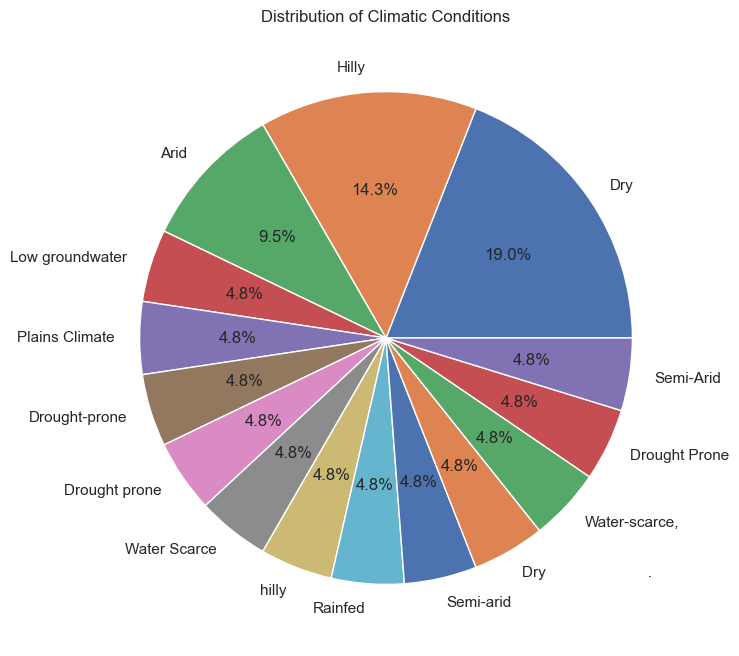

In [26]:
climate_counts = df["Climatic Conditions"].value_counts()

plt.figure(figsize=(8,8))
plt.pie(climate_counts, labels=climate_counts.index, autopct='%1.1f%%')
plt.title("Distribution of Climatic Conditions")
plt.show()

2.Climate Conditions vs Land Size (Heatmap)

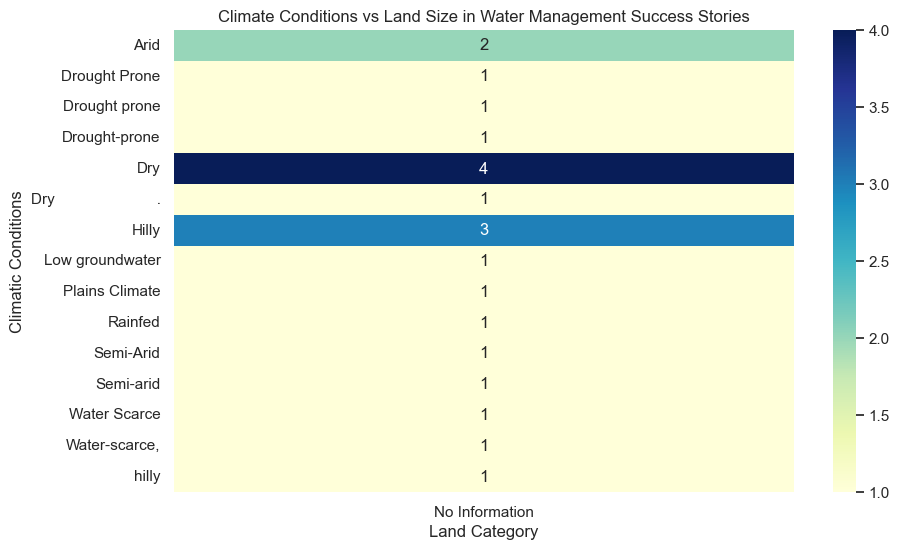

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Relationship table
climate_land = pd.crosstab(df["Climatic Conditions"], df["Land Category"])

plt.figure(figsize=(10,6))
sns.heatmap(climate_land, annot=True, cmap="YlGnBu")

plt.title("Climate Conditions vs Land Size in Water Management Success Stories")
plt.xlabel("Land Category")
plt.ylabel("Climatic Conditions")

plt.show()

3.Top Crops Used

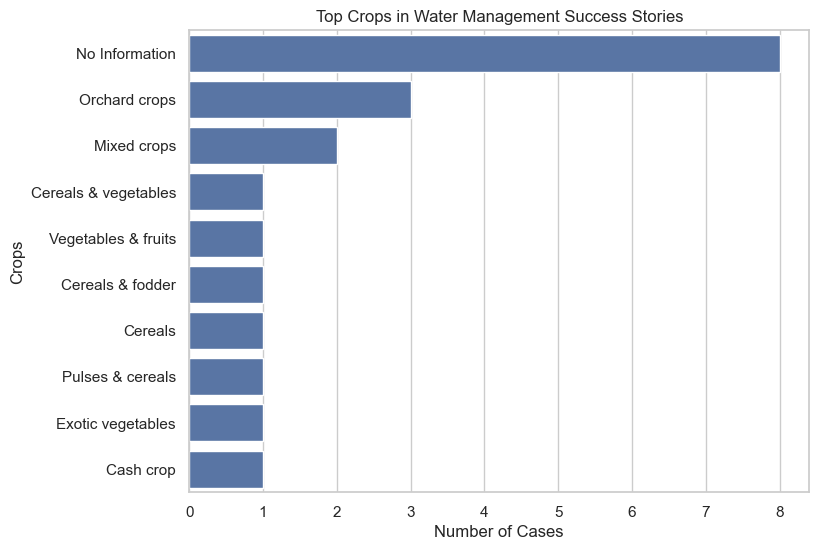

In [28]:
crop_counts = df["Crops"].value_counts().head(10)

plt.figure(figsize=(8,6))
sns.barplot(x=crop_counts.values, y=crop_counts.index)

plt.title("Top Crops in Water Management Success Stories")
plt.xlabel("Number of Cases")
plt.ylabel("Crops")
plt.show()

4.Impact of Climate on Income Results


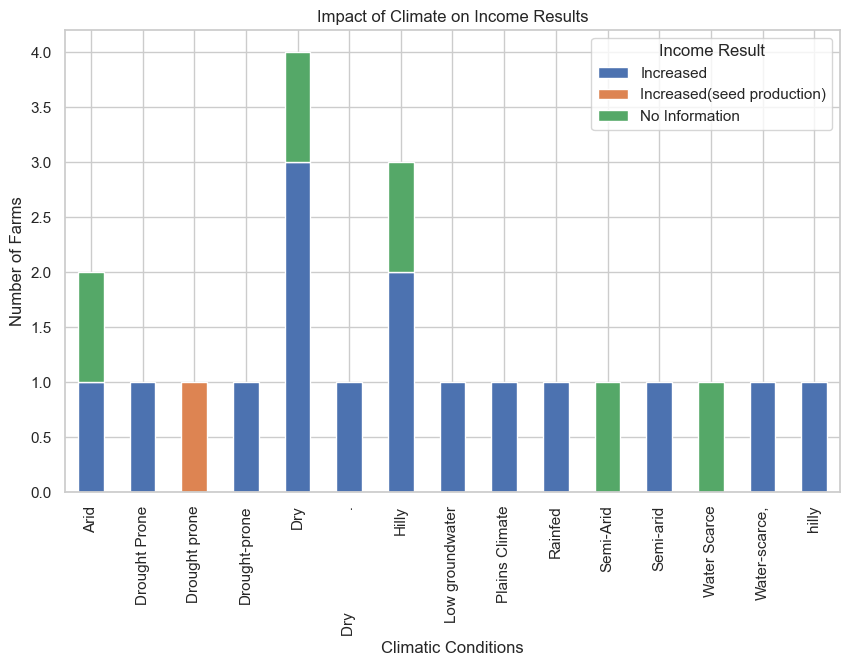

In [29]:
climate_income = pd.crosstab(df["Climatic Conditions"], df["Income Result"])

climate_income.plot(kind="bar", stacked=True, figsize=(10,6))

plt.title("Impact of Climate on Income Results")
plt.xlabel("Climatic Conditions")
plt.ylabel("Number of Farms")
plt.legend(title="Income Result")
plt.show()

5.Applicability in Chhattisgarh

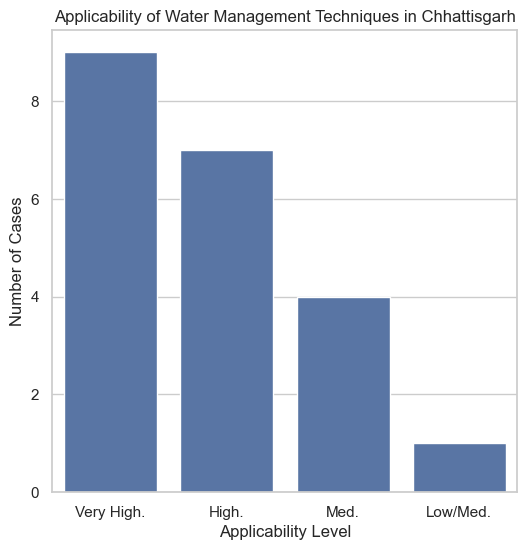

In [30]:
app_counts = df["Applicability in Chhattisgarh"].value_counts()

plt.figure(figsize=(6,6))
sns.barplot(x=app_counts.index, y=app_counts.values)

plt.title("Applicability of Water Management Techniques in Chhattisgarh")
plt.xlabel("Applicability Level")
plt.ylabel("Number of Cases")
plt.show()

In [31]:
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8,6)